# 一緒に買われる商品を探す：アソシエーション分析

## 概要

売上ランキングだけでは、どの商品を隣に置くか、何を一緒に薦めるかは決まらない。本記事は『マーケティングサイエンスの理論と実践』第8章「併買パターンを発見する」の紹介である。購買記録から商品の組み合わせを抽出する方法と、その結果の読み方を扱う。

本章と同じ順に、候補が増える問題、AprioriとEclat、支持度・確信度・リフト値を説明し、公開食品購買データでPythonの実装を確認する。

### 実行環境

仮想環境は **wa-src(3.14.6)**、Pythonは **3.14.6** である。主にPolars、pandas、mlxtend、NumPy、Matplotlibを使う。配布用ZIPを展開し、同梱の`requirements.txt`で依存ライブラリを用意して上から実行する。入力CSVは`data`、図の保存先は`08_nb_files`であり、保存形式はSVGである。小数の表示は有効数字3桁にそろえ、計算には丸める前の値を使う。

In [1]:
from pathlib import Path
from pprint import pprint
from collections import Counter
from importlib.metadata import version
from io import BytesIO
from base64 import b64encode
import platform

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib_fontja  # 日本語のフォントを設定する。
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator, ScalarFormatter
from mlxtend.frequent_patterns import apriori, association_rules
from IPython.display import Latex, display

# Notebookのフォルダー、またはリポジトリ直下から実行できる。
BASE = Path.cwd()
if (BASE / "blog/08/08_nb.ipynb").exists():
    BASE = BASE / "blog/08"
FIG_DIR = BASE / "08_nb_files"
FIG_DIR.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロを残して、有効数字3桁で表示する。"""
    return format(float(value), "#.3g").removesuffix(".")


def show_math(tex):
    # 重要式は \( ... \) で記述し、出力時は $$ ... $$ に統一する。
    # HTMLへの変換でも区切りが二重にならないようにする。
    tex = tex.strip()
    if tex.startswith(r"\(") and tex.endswith(r"\)"):
        tex = tex[2:-2].strip()
    display(Latex("$$\n" + tex + "\n$$"))


def save_svg(fig, filename):
    """SVGを保存し、NotebookにはSVGと閲覧用PNGを埋め込む。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(
                    lambda x, _: str(int(x)) if float(x).is_integer() else sig3(x)
                ))
    path = FIG_DIR / filename
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    # 未信頼のNotebookでも図を読めるよう、PNGは出力欄だけに埋め込む。
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    width = min(950, int(fig.get_figwidth() * 96))
    display({
        "image/svg+xml": path.read_text(),
        "image/png": b64encode(preview.getvalue()).decode("ascii"),
    }, raw=True, metadata={
        "image/svg+xml": {"width": width},
        "image/png": {"width": width},
    })


np.set_printoptions(formatter={"float_kind": sig3})
pd.options.display.float_format = sig3
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "svg.fonttype": "path",
    "svg.hashsalt": "blog08",
})
BLUE, ORANGE, GRAY = "#336A91", "#B85D29", "#B5BDC4"

print("仮想環境：wa-src(3.14.6)")
print(f"Python：{platform.python_version()}")
for package in ("polars", "pandas", "mlxtend", "numpy", "matplotlib", "pyarrow"):
    print(f"{package}：{version(package)}")

仮想環境：wa-src(3.14.6)
Python：3.14.6
polars：2.1.0
pandas：2.3.3
mlxtend：0.24.0
numpy：2.4.6
matplotlib：3.11.2
pyarrow：23.0.1


## 1. なぜ組み合わせを絞る必要があるか

「一緒に買ってもらう商品を増やしたい」という課題を、「商品$X$と一緒に薦める商品$Y$を選ぶ」という分析に置き換える。アソシエーション分析では、買い物ごとに現れる商品の集合を数え、その後で$X\Rightarrow Y$というルールを作る。

商品が$n$種類あると、部分集合は各商品を選ぶか選ばないかの$2^n$通りである。空集合と商品1個の集合を除くと、商品2個以上の候補数$I_n$を得る。商品$k$個の集合からは、条件部と結論部が空になる場合を除き、$2^k-2$通りのルールを作れる。二項定理を使うと、ルールの総候補数$R_n$も計算できる。

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

商品10種類：集合の候補 1,013、ルールの候補 57,002


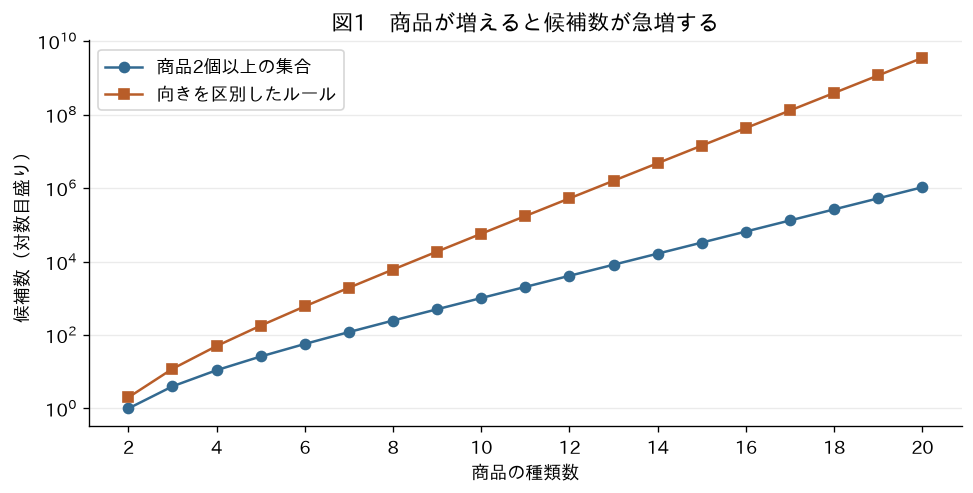

In [2]:
show_math(r"\(I_n=\sum_{k=2}^{n}\binom{n}{k}=2^n-1-n\)")
show_math(r"""
\(
\begin{aligned}
R_n&=\sum_{k=2}^{n}\binom{n}{k}(2^k-2)\\
&=\left\{\sum_{k=0}^{n}\binom{n}{k}2^k-1-2n\right\}
 -2\left\{\sum_{k=0}^{n}\binom{n}{k}-1-n\right\}\\
&=\{(1+2)^n-1-2n\}-2\{(1+1)^n-1-n\}\\
&=3^n-2^{n+1}+1.
\end{aligned}
\)
""")

# 商品数を変え、候補数の増え方を対数目盛りで確認する。
n = np.arange(2, 21)
itemset_counts = 2 ** n - n - 1
rule_counts = 3 ** n - 2 ** (n + 1) + 1
print(f"商品10種類：集合の候補 {2 ** 10 - 10 - 1:,}、ルールの候補 {3 ** 10 - 2 ** 11 + 1:,}")

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.semilogy(n, itemset_counts, "o-", color=BLUE, label="商品2個以上の集合")
ax.semilogy(n, rule_counts, "s-", color=ORANGE, label="向きを区別したルール")
ax.set(xlabel="商品の種類数", ylabel="候補数（対数目盛り）",
       title="図1　商品が増えると候補数が急増する")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.250)
ax.legend()
save_svg(fig, "01_candidates.svg")

商品10種類でも、ルールは57,002通りになる。すべてを調べて読むのは難しい。まず、出現頻度の低い集合を除外する必要がある。

## 2. 頻出する集合を抽出し、ルールを評価する

### Apriori：小さい集合から候補を絞る

支持度は、その集合を含む買い物の件数を全件数で割った値である。支持度が設定した最小支持度以上なら、頻出アイテムセットとして残す。

集合$S$に商品を足して$U$にすると、$U$を含む買い物は必ず$S$も含む。$T(S)$を$S$が現れる買い物IDの集合とすると、次の関係になる。

<IPython.core.display.Latex object>

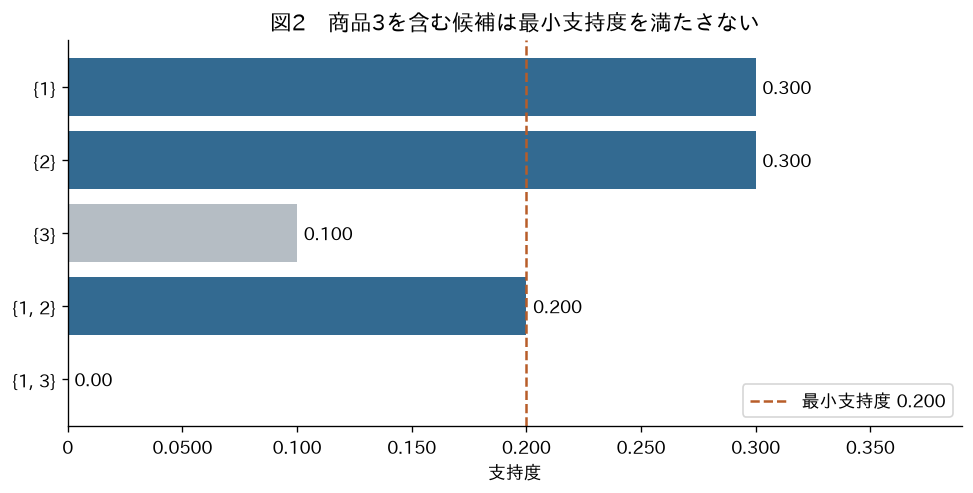

In [3]:
show_math(r"""
\(
\begin{aligned}
S\subseteq U&\ \Rightarrow\ T(U)\subseteq T(S)
\ \Rightarrow\ |T(U)|\leq |T(S)|,\\
\mathrm{Supp}(U)&=\frac{|T(U)|}{N}
\leq\frac{|T(S)|}{N}=\mathrm{Supp}(S).
\end{aligned}
\)
""")

# 説明用の10件。商品3が少ないので、それを含む集合も頻出にならない。
toy = [{1, 2}, {1, 2}, {3}, {1}, {2}, {4}, {5}, {6}, {7}, {8}]
candidates = [{1}, {2}, {3}, {1, 2}, {1, 3}]
supports = [sum(s <= basket for basket in toy) / len(toy) for s in candidates]
labels = ["{1}", "{2}", "{3}", "{1, 2}", "{1, 3}"]
min_support_toy = 0.200

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
bars = ax.barh(labels, supports,
               color=[BLUE if s >= min_support_toy else GRAY for s in supports])
ax.bar_label(bars, labels=[sig3(s) for s in supports], padding=4)
ax.axvline(min_support_toy, color=ORANGE, linestyle="--", label="最小支持度 0.200")
ax.invert_yaxis()
ax.set(xlim=(0, 0.390), xlabel="支持度",
       title="図2　商品3を含む候補は最小支持度を満たさない")
ax.legend(loc="lower right")
save_svg(fig, "02_pruning.svg")

したがって、頻出しない集合を含む大きな候補も除外できる。Aprioriは商品1個、2個、3個の順に、この性質で候補を減らす。図2の灰色は支持度を説明するための表示であり、実際の探索では、商品3を除いた時点でそれを含む組み合わせを作らずに済む。

### Eclat：買い物IDの共通部分を使う

Eclatは商品ごとに買い物IDを保持し、共通するIDの件数から支持度を計算する。図2の商品1と2なら、共通するIDは1と2の2件である。集合を一つずつ拡張する深さ優先探索を使い、最小支持度を下回った枝は打ち切る。

In [4]:
# 買い物の番号は1から始める。& は集合の共通部分を求める演算である。
tid_1 = {i for i, basket in enumerate(toy, start=1) if 1 in basket}
tid_2 = {i for i, basket in enumerate(toy, start=1) if 2 in basket}
common_ids = tid_1 & tid_2
pprint({"商品1": sorted(tid_1), "商品2": sorted(tid_2), "共通ID": sorted(common_ids)})
show_math(r"""
\(
T(\{1,2\})=\{1,2,4\}\cap\{1,2,5\}=\{1,2\},\qquad
\mathrm{Supp}(\{1,2\})=\frac{2}{10}=0.200.
\)
""")

{'共通ID': [1, 2], '商品1': [1, 2, 4], '商品2': [1, 2, 5]}


<IPython.core.display.Latex object>

Eclatでは記録の読み直しを減らせる場合がある一方、ID集合を保持するメモリが必要になる。本章では、商品の種類数や1回の買い物の大きさに応じて手法を選ぶ。

### 支持度・確信度・リフト値

$X$と$Y$は重複しない商品集合とする。全買い物件数を$N$、$X$を含む件数を$n_X$、$Y$を含む件数を$n_Y$、両方を含む件数を$n_{XY}$と置く。$P(X)$は、買い物が$X$を含む確率を表す。3指標を件数から順に計算する。

In [5]:
show_math(r"""
\(
\begin{aligned}
\mathrm{Supp}(X,Y)&=\frac{n_{XY}}{N}=P(X\cap Y),\\
\mathrm{Conf}(X\Rightarrow Y)
&=\frac{\mathrm{Supp}(X,Y)}{\mathrm{Supp}(X)}
=\frac{n_{XY}/N}{n_X/N}
=\frac{n_{XY}}{n_X}=P(Y\mid X).
\end{aligned}
\)
""")
show_math(r"""
\(
\begin{aligned}
\mathrm{Lift}(X\Rightarrow Y)
&=\frac{\mathrm{Conf}(X\Rightarrow Y)}{\mathrm{Supp}(Y)}
=\frac{n_{XY}/n_X}{n_Y/N}\\
&=\frac{Nn_{XY}}{n_Xn_Y}
=\frac{P(X\cap Y)}{P(X)P(Y)}.
\end{aligned}
\)
""")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

支持度は対象の規模、確信度は$X$を買ったときに$Y$も買う割合を示す。ただし、人気商品は何と組み合わせても確信度が高くなり得る。そこで、全体で$Y$が買われる割合を分母にしたリフト値も見る。

独立なら$P(X\cap Y)=P(X)P(Y)$なのでリフト値は1である。1より大きければ独立の場合より一緒に現れやすく、1未満なら現れにくい。ただし、1を超えただけで統計的に確かな関係や施策の効果が示されるわけではない。

## 3. Pythonで食品の購買記録を分析する

### 買い物ごとに商品をまとめる

本章と同じGroceriesデータを読み込む。38,765行の商品明細から会員番号、購入日、商品名を選び、同じ会員・同じ日の商品をまとめる。同じ商品の重複は除く。取引IDがないため、同じ日に複数回買った場合も一つにまとめられる点に注意が必要である。

商品明細：38,765行、買い物：14,963件、商品：167種類
[['tropical fruit', 'rolls/buns', 'candy'],
 ['whole milk', 'tropical fruit', 'chocolate'],
 ['pip fruit', 'other vegetables', 'flour']]


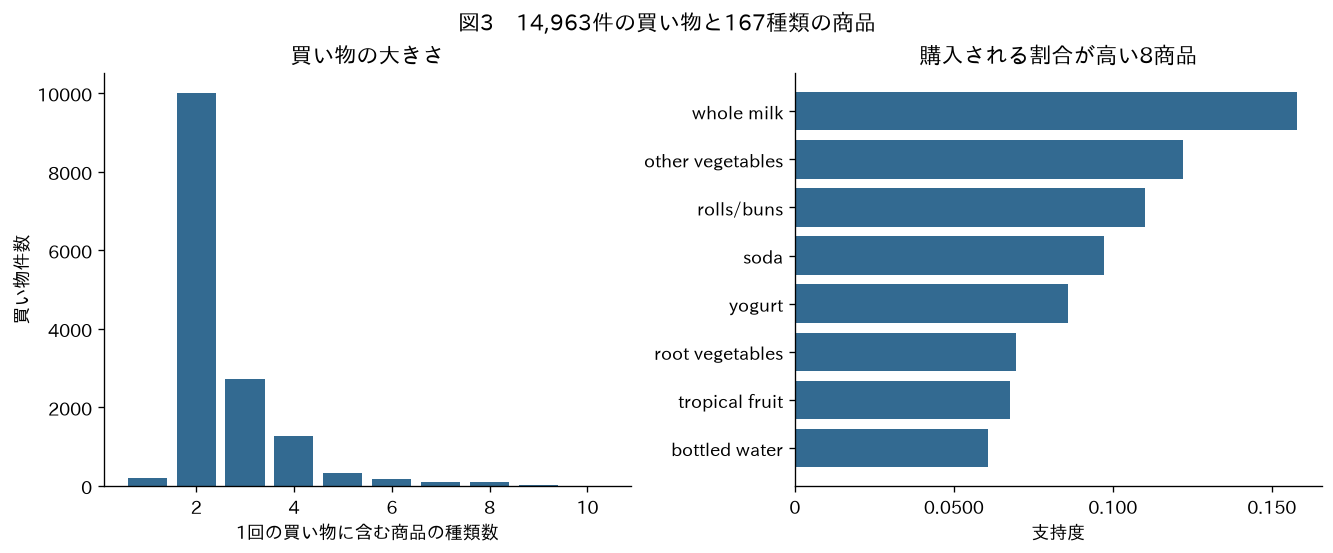

In [6]:
raw = pl.read_csv(BASE / "data/Groceries data.csv.gz").select(
    ["Member_number", "Date", "itemDescription"]
)
transactions_df = raw.group_by(
    ["Member_number", "Date"], maintain_order=True
).agg(pl.col("itemDescription").unique(maintain_order=True).alias("items"))
transactions = transactions_df["items"].to_list()
N = len(transactions)
all_items = raw["itemDescription"].unique().sort().to_list()

print(f"商品明細：{raw.height:,}行、買い物：{N:,}件、商品：{len(all_items)}種類")
pprint(transactions[:3], width=90)

# 商品は各買い物の中で一度だけ数える。
size_counts = Counter(map(len, transactions))
item_counts = Counter(item for basket in transactions for item in basket)
top_items = item_counts.most_common(8)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].bar(list(sorted(size_counts)), [size_counts[k] for k in sorted(size_counts)], color=BLUE)
axes[0].set(xlabel="1回の買い物に含む商品の種類数", ylabel="買い物件数",
            title="買い物の大きさ")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].barh([name for name, _ in top_items], [count / N for _, count in top_items], color=BLUE)
axes[1].set(xlabel="支持度", title="購入される割合が高い8商品")
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=4))
fig.suptitle("図3　14,963件の買い物と167種類の商品")
save_svg(fig, "03_transactions.svg")

図3ではwhole milkの支持度が0.158と高い。こうした商品を含む併買を、そのまま強い関係と読まないことが大切である。

### 購入の有無を表し、Aprioriを実行する

行を買い物、列を商品とする行列$\mathbf{B}$を作る。購入ありをTrue、なしをFalseとし、mlxtendに渡すためpandasへ変換する。図4はその一部である。

購入有無の行列：14,963行 × 167列


<IPython.core.display.Latex object>

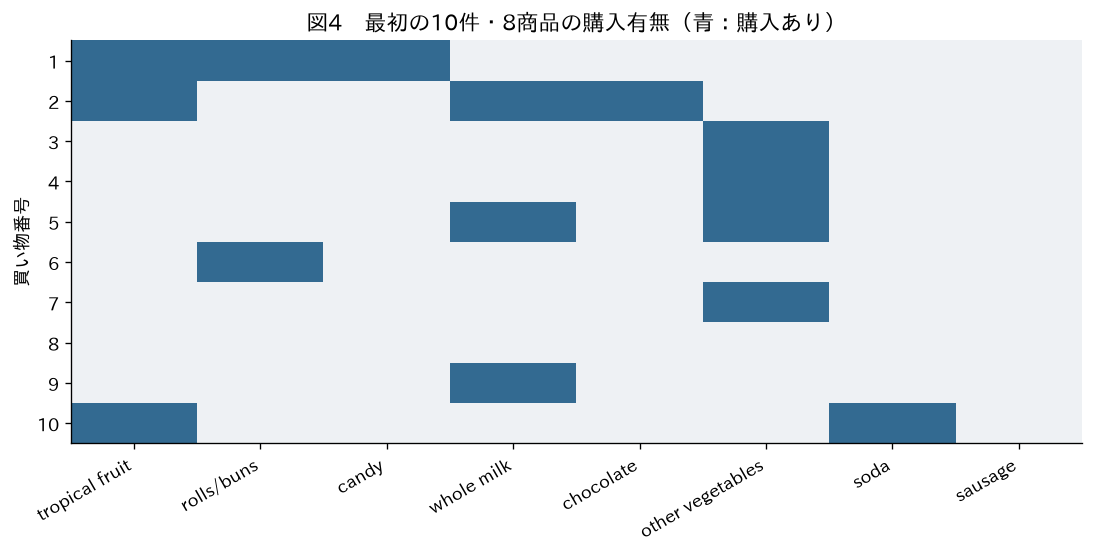

In [7]:
# 書籍と同じく、各商品を含むかどうかをPolarsで表す。
baskets_pl = pl.DataFrame({
    item: [item in transaction for transaction in transactions]
    for item in all_items
})
baskets = baskets_pl.to_pandas()
print(f"購入有無の行列：{baskets.shape[0]:,}行 × {baskets.shape[1]}列")
show_math(r"\(\mathbf{B}=(b_{ij})\in\{0,1\}^{14963\times167}\)")

preview_items = ["tropical fruit", "rolls/buns", "candy", "whole milk",
                 "chocolate", "other vegetables", "soda", "sausage"]
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.imshow(baskets[preview_items].iloc[:10].to_numpy().astype(int),
          cmap=ListedColormap(["#EEF1F4", BLUE]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(preview_items)), preview_items, rotation=30, ha="right")
ax.set_yticks(range(10), range(1, 11))
ax.set(ylabel="買い物番号", title="図4　最初の10件・8商品の購入有無（青：購入あり）")
save_svg(fig, "04_purchase_matrix.svg")

最小支持度は本章と同じ0.00500とする。14,963件では75件以上に現れる集合が残る。ここでは126個が抽出され、内訳は商品1個の集合が89個、商品2個の集合が37個である。

頻出アイテムセット：126個
                           商品  support
other vegetables + whole milk   0.0148
      rolls/buns + whole milk   0.0140
            soda + whole milk   0.0116
          whole milk + yogurt   0.0112
other vegetables + rolls/buns   0.0106


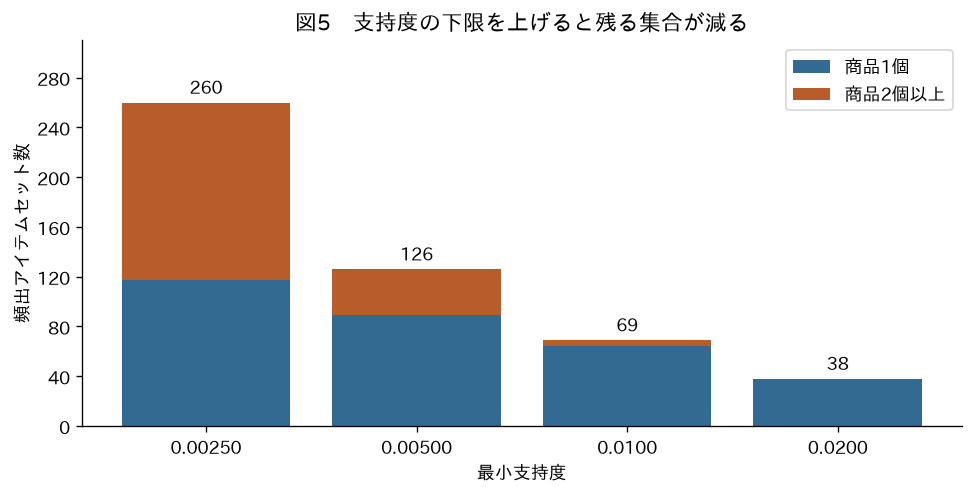

In [8]:
MIN_SUPPORT = 0.00500
frequent_itemsets = apriori(baskets, min_support=MIN_SUPPORT, use_colnames=True)

# 集合の中の商品名を並べ替え、再実行しても読みやすい表示にする。
def item_label(items):
    return " + ".join(sorted(items))


pair_table = frequent_itemsets.loc[
    frequent_itemsets["itemsets"].map(len) == 2
].copy()
pair_table["商品"] = pair_table["itemsets"].map(item_label)
pair_table = pair_table.sort_values(["support", "商品"], ascending=[False, True])
print(f"頻出アイテムセット：{len(frequent_itemsets)}個")
print(pair_table[["商品", "support"]].head().to_string(index=False, float_format=sig3))

# 最小支持度を変えて、残る集合の数を比較する。
thresholds = [0.00250, 0.00500, 0.0100, 0.0200]
counts = []
for threshold in thresholds:
    found = apriori(baskets, min_support=threshold, use_colnames=True)
    sizes = found["itemsets"].map(len)
    counts.append((int((sizes == 1).sum()), int((sizes >= 2).sum())))

single_counts, multiple_counts = np.array(counts).T
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
positions = np.arange(len(thresholds))
ax.bar(positions, single_counts, color=BLUE, label="商品1個")
bars = ax.bar(positions, multiple_counts, bottom=single_counts,
              color=ORANGE, label="商品2個以上")
ax.bar_label(bars, labels=[str(a + b) for a, b in counts], padding=4)
ax.set_xticks(positions, [sig3(value) for value in thresholds])
ax.set(xlabel="最小支持度", ylabel="頻出アイテムセット数", ylim=(0, 310),
       title="図5　支持度の下限を上げると残る集合が減る")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
save_svg(fig, "05_support_threshold.svg")

図5では、下限0.0200で商品2個以上の集合がなくなる。下限を高くすると小規模な組み合わせを見落とし、低くすると確認する候補が増える。値は対象件数や実施できる施策の規模に合わせて決める。

### ルールを作り、結果を読む

本章の条件に合わせ、確信度0.0200以上のルールを生成し、リフト値1以上に絞る。74件から6件が残るが、向きを逆にしたものをまとめると3組である。

確信度で抽出：74件、リフト値で絞った後：6件
                           ルール  support  confidence  lift
                sausage → soda  0.00595      0.0986  1.01
                soda → sausage  0.00595      0.0613  1.01
              sausage → yogurt  0.00575      0.0952  1.11
              yogurt → sausage  0.00575      0.0669  1.11
frankfurter → other vegetables  0.00515       0.136  1.12
other vegetables → frankfurter  0.00515      0.0421  1.12


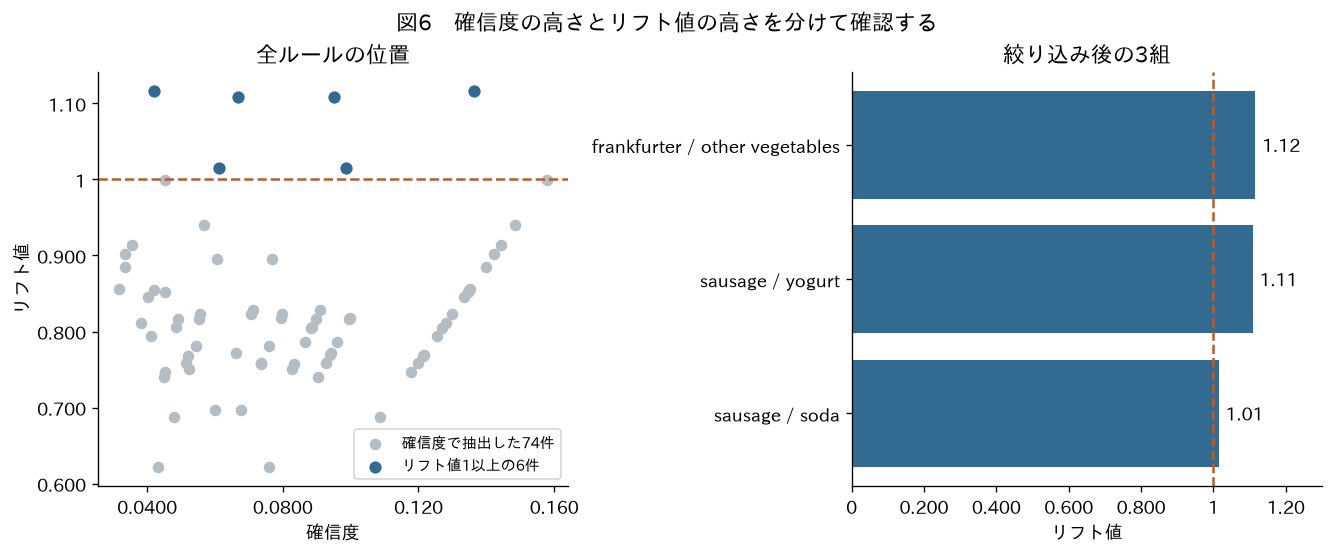

In [9]:
all_rules = association_rules(
    frequent_itemsets, metric="confidence", min_threshold=0.0200
)
rules = all_rules.loc[all_rules["lift"] >= 1].copy()
rules["ルール"] = (
    rules["antecedents"].map(item_label) + " → " + rules["consequents"].map(item_label)
)
rules = rules.sort_values(["support", "confidence", "lift", "ルール"],
                         ascending=[False, False, False, True])
print(f"確信度で抽出：{len(all_rules)}件、リフト値で絞った後：{len(rules)}件")
print(rules[["ルール", "support", "confidence", "lift"]].to_string(
    index=False, float_format=sig3
))

# リフト値は向きを逆にしても同じなので、右図では1組につき1回描く。
rules["組"] = [
    " / ".join(sorted(a | b))
    for a, b in zip(rules["antecedents"], rules["consequents"])
]
unique_pairs = rules.drop_duplicates("組").sort_values("lift")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].scatter(all_rules["confidence"], all_rules["lift"], color=GRAY,
                s=35, label="確信度で抽出した74件")
axes[0].scatter(rules["confidence"], rules["lift"], color=BLUE,
                s=40, label="リフト値1以上の6件")
axes[0].axhline(1, color=ORANGE, linestyle="--")
axes[0].set(xlabel="確信度", ylabel="リフト値", title="全ルールの位置")
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=4))
axes[0].legend(loc="lower right", fontsize=9)
bars = axes[1].barh(unique_pairs["組"], unique_pairs["lift"], color=BLUE)
axes[1].bar_label(bars, labels=[sig3(x) for x in unique_pairs["lift"]], padding=4)
axes[1].axvline(1, color=ORANGE, linestyle="--")
axes[1].set(xlim=(0, 1.30), xlabel="リフト値", title="絞り込み後の3組")
fig.suptitle("図6　確信度の高さとリフト値の高さを分けて確認する")
save_svg(fig, "06_rules.svg")

本章で取り上げるsausageからsodaへのルールを、元の件数で確かめる。sausageを含む買い物は903件、sodaは1,453件、両方を含む買い物は89件である。

{'sausage': 903, 'soda': 1453, '両方': 89, '全件数': 14963}


<IPython.core.display.Latex object>

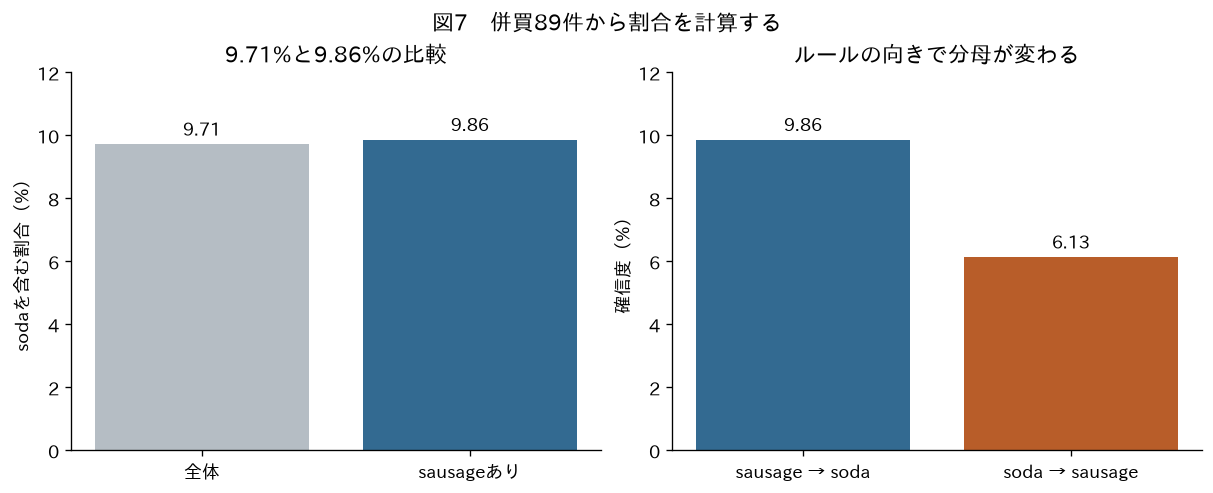

In [10]:
x = baskets["sausage"]
y = baskets["soda"]
n_x, n_y, n_xy = int(x.sum()), int(y.sum()), int((x & y).sum())
support = n_xy / N
confidence = n_xy / n_x
baseline = n_y / N
lift = confidence / baseline
reverse_confidence = n_xy / n_y
pprint({"全件数": N, "sausage": n_x, "soda": n_y, "両方": n_xy})

# 分母・分子は元の整数のまま計算し、表示時だけ丸める。
show_math(rf"""
\(
\begin{{aligned}}
\mathrm{{Supp}}&=\frac{{{n_xy}}}{{{N}}}\approx {sig3(support)},\\
\mathrm{{Conf}}&=\frac{{{n_xy}/{N}}}{{{n_x}/{N}}}
=\frac{{{n_xy}}}{{{n_x}}}\approx {sig3(confidence)},\\
\mathrm{{Lift}}&=\frac{{{n_xy}/{n_x}}}{{{n_y}/{N}}}
=\frac{{{n_xy}\times {N}}}{{{n_x}\times {n_y}}}\approx {sig3(lift)}.
\end{{aligned}}
\)
""")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
values = [100 * baseline, 100 * confidence]
bars = axes[0].bar(["全体", "sausageあり"], values, color=[GRAY, BLUE])
axes[0].bar_label(bars, labels=[sig3(v) for v in values], padding=4)
axes[0].set(ylim=(0, 12), ylabel="sodaを含む割合（%）", title="9.71%と9.86%の比較")
values = [100 * confidence, 100 * reverse_confidence]
bars = axes[1].bar(["sausage → soda", "soda → sausage"], values, color=[BLUE, ORANGE])
axes[1].bar_label(bars, labels=[sig3(v) for v in values], padding=4)
axes[1].set(ylim=(0, 12), ylabel="確信度（%）", title="ルールの向きで分母が変わる")
fig.suptitle("図7　併買89件から割合を計算する")
save_svg(fig, "07_rule_interpretation.svg")

全体でsodaを買う割合は9.71%、sausageがある場合は9.86%である。リフト値は1.01で、併買の関係は弱い。逆向きの確信度は6.13%になるが、リフト値は変わらない。図7では、比べる相手と分母の違いを確認できる。

このルールを試すなら、sausageをかごに入れ、sodaをまだ入れていない利用者が推薦対象になる。ただし、この差だけから売上が増えるとは判断できない。私は、数値の大きさと対象件数を具体的に説明できる点が、この手法の使いやすさだと考える。

## 結論

この記事では、併買の候補をAprioriとEclatで絞る考え方と、3指標による評価を説明し、Pythonで本章の分析結果を確認した。

アソシエーションルールは施策の候補であり、因果関係を示さない。推薦する場合としない場合に利用者を無作為に分け、購入点数や費用を差し引いた利益を比較する。判定の期間と基準を先に決め、結果に応じて拡大・見直し・中止を判断する。

[本書](https://gihyo.jp/book/2026/978-4-297-16025-8)では、分析の課題設定から施策の検証までを扱う。[サポートページ](https://github.com/gihyo-book/marketing_science_book)には本章のコード全体に加え、AprioriとEclatをライブラリに頼らず実装する例も掲載されている。

参考データ：Rashik Rahman, [Groceries dataset for Market Basket Analysis (MBA)](https://www.kaggle.com/datasets/rashikrahmanpritom/groceries-dataset-for-market-basket-analysismba), Version 2。本章でCC0として案内しているCSVを、同梱データとして無加工で圧縮した。